# SC4002 Group Assignment — Joint intent classification and slot filling on MASSIVE en-US

| Section | Contents |
|---|---|
| 1 | Setup |
| 2 | Load and verify the dataset (official splits) |
| 3 | Preprocessing (inputs and labels) |
| 4 | Shared evaluation functions (used for every experiment) |
| 5 | **Stage 1** — independent baseline (no generative AI) |
| 6 | **Stage 2** — AI-enhanced system: architecture, parameter count |
| 7 | Stage 2 — training and checkpoint selection (dev only) |
| 8 | Stage 2 — final evaluation of the frozen checkpoint (validation + single test run) |
| 9 | Results table |
| 10 | Stage 2 — error analysis on the test predictions |

Data use: the **train** split fits every parameter and vocabulary; the **dev** split selects epochs and the ensemble
vote threshold; the **test** split is scored exactly once, in Section 8, after everything is frozen.
Only `utt` is ever used as model input.

## 1. Setup

In [1]:
import os, re, json, time, math, random, copy, zlib, platform
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = os.path.abspath(".")
MASSIVE_PATH = os.path.join(ROOT, "1.0", "data", "en-US.jsonl")
GLOVE_PATH = os.path.join(ROOT, "embeddings", "glove.6B.300d.txt")        # word vectors (allowed pretrained input)
FASTTEXT_PATH = os.path.join(ROOT, "embeddings", "crawl-300d-2M.vec")
CKPT_DIR = os.path.join(ROOT, "checkpoints", "stage2")
LOG_DIR = os.path.join(ROOT, "logs", "stage2")
for d in (CKPT_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

python 3.12.14 | torch 2.6.0+cu124 | device cuda (Tesla V100-PCIE-32GB)


## 2. Load and verify the dataset

`1.0/data/en-US.jsonl` from the official MASSIVE 1.0 archive, partitioned by its own `partition` field.
`annot_utt` is parsed into word-level BIO tags and the gold set of `(slot type, span text)` pairs; the parse is
checked to reproduce `utt` word for word.

In [2]:
SLOT_RE = re.compile(r"\[\s*([^\[\]:]+?)\s*:\s*([^\[\]]*?)\s*\]")


def parse_annot(annot_utt):
    # 'wake me up at [time : five am]' -> tokens, BIO tags, gold set of (slot_type, span_text)
    tokens, tags, spans, pos = [], [], set(), 0
    for m in SLOT_RE.finditer(annot_utt):
        outside = annot_utt[pos:m.start()].split()
        tokens += outside
        tags += ["O"] * len(outside)
        slot_type, words = m.group(1).strip(), m.group(2).split()
        tokens += words
        tags += [f"B-{slot_type}"] + [f"I-{slot_type}"] * (len(words) - 1)
        spans.add((slot_type, " ".join(words)))
        pos = m.end()
    outside = annot_utt[pos:].split()
    tokens += outside
    tags += ["O"] * len(outside)
    return tokens, tags, spans


def to_example(r):
    tokens, tags, spans = parse_annot(r["annot_utt"])
    assert tokens == r["utt"].split(), f"annot_utt and utt disagree for id {r['id']}"
    return {"id": r["id"], "utt": r["utt"], "tokens": tokens, "tags": tags, "gold_spans": spans,
            "intent": r["intent"], "scenario": r["intent"].split("_", 1)[0]}


with open(MASSIVE_PATH, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]
raw = {n: [r for r in records if r["partition"] == n] for n in ("train", "dev", "test")}
for name, label in (("train", "training"), ("dev", "validation"), ("test", "test")):
    print(f"{label:<10} ({name}): {len(raw[name]):,} examples")
assert len(records) == 16_521
assert (len(raw["train"]), len(raw["dev"]), len(raw["test"])) == (11_514, 2_033, 2_974)
data = {n: [to_example(r) for r in raw[n]] for n in raw}
ex = data["train"][0]
print("\nexample:", ex["utt"], "|", ex["intent"], "|", sorted(ex["gold_spans"]))

training   (train): 11,514 examples
validation (dev): 2,033 examples
test       (test): 2,974 examples



example: wake me up at nine am on friday | alarm_set | [('date', 'friday'), ('time', 'nine am')]


## 3. Preprocessing

Everything here is fitted on the **train split only**.

* **Labels** — 60 intents, 18 scenarios (the prefix of the intent name), 55 slot types → 111 BIO tags.
* **Units** — each whitespace token is split at English clitics (`what's` → `what` `'s`; `p.` → `p`), so word vectors
  are found for more of the input. Every token keeps the index of its first unit, so tags stay word-level and spans
  are always whole words of `utt`.
* **Per-unit inputs** — (a) a frozen 600-d vector = GloVe-6B-300d ⊕ fastText crawl-300d (rows: all train units plus
  the 2,000 most frequent GloVe words), (b) a trainable 100-d unit embedding with frequency-based word dropout
  (rare words are replaced by `<unk>` more often during training), (c) a character CNN, (d) hashed character 3–5-gram
  embeddings. Words never seen in train still get (a), (c), (d).

In [3]:
PAD, UNK = "<pad>", "<unk>"
MAX_SPAN = 10                    # longest slot span (words) the span head scores; longest train span is 10


class Vocab:
    def __init__(self, items, specials=(PAD, UNK)):
        self.itos = list(specials) + [x for x in items if x not in specials]
        self.stoi = {x: i for i, x in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def get(self, x):
        return self.stoi.get(x, self.stoi.get(UNK, 0))


class Labels:
    # Intent / scenario / BIO tag inventories, fitted on train only.
    def __init__(self, train):
        self.intents = Vocab(sorted({e["intent"] for e in train}), specials=())
        self.scenarios = Vocab(sorted({e["scenario"] for e in train}), specials=())
        self.slot_types = sorted({t[2:] for e in train for t in e["tags"] if t != "O"})
        self.tags = Vocab(["O"] + [f"{p}-{s}" for s in self.slot_types for p in ("B", "I")], specials=())
        self.i2s = torch.tensor([self.scenarios.stoi[i.split("_", 1)[0]] for i in self.intents.itos])
        self.tag_type = torch.tensor([0] + [self.slot_types.index(t[2:]) + 1 for t in self.tags.itos[1:]])
        self.tag_is_b = torch.tensor([t.startswith("B-") for t in self.tags.itos])


labels = Labels(data["train"])
print(f"{len(labels.intents)} intents | {len(labels.scenarios)} scenarios | {len(labels.slot_types)} slot types | "
      f"{len(labels.tags)} BIO tags")
assert len(labels.intents) == 60 and len(labels.slot_types) == 55
assert max(len(s.split()) for e in data["train"] for _, s in e["gold_spans"]) <= MAX_SPAN

60 intents | 18 scenarios | 55 slot types | 111 BIO tags


In [4]:
CLITIC_RE = re.compile(r"^(.+?)(n't|'s|'re|'ve|'ll|'d|'m)$")


def clitic_units(token):
    if re.fullmatch(r"[a-z]\.", token):
        return [token[0]]
    m = CLITIC_RE.match(token)
    return [m.group(1), m.group(2)] if m else [token]


def split_units(tokens):
    # units for the encoder, index of each token's first unit, token index of every unit
    units, first, owner = [], [], []
    for ti, t in enumerate(tokens):
        first.append(len(units))
        us = clitic_units(t)
        units.extend(us)
        owner.extend([ti] * len(us))
    return units, first, owner


def char_ngrams(unit, buckets, n_min=3, n_max=5, max_grams=40):
    w = f"<{unit}>"
    grams = [w] + [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]
    return [1 + zlib.crc32(g.encode("utf-8")) % buckets for g in grams[:max_grams]]


def vector_keys(w):
    # lookup keys for a unit: itself, stripped of punctuation, and (for clitics / hyphenated words) its parts
    s = w.strip(".,!?;:\"()")
    keys = [w, s, s.replace(".", "")]
    m = re.fullmatch(r"(.+?)(n't|'s|'re|'ve|'ll|'d|'m|')", s)
    if m:
        keys.append(tuple(p for p in m.groups() if p))
    parts = [p for p in re.split(r"[-./&]", s) if p]
    if len(parts) > 1:
        keys.append(tuple(parts))
    return keys


def needed_keys(words):
    return {p for w in words for k in vector_keys(w) for p in (k if isinstance(k, tuple) else (k,))}


def read_vectors(path, wanted, top_k=0):
    vecs, top = {}, []
    with open(path, encoding="utf-8", errors="ignore") as f:
        for rank, line in enumerate(f):
            word, _, rest = line.rstrip("\n").partition(" ")
            if rank == 0 and rest.count(" ") < 5:          # fastText header line
                continue
            if word in wanted or len(top) < top_k:
                v = np.asarray(rest.split(" "), dtype=np.float32)
                if v.shape[0] != 300:
                    continue
                vecs[word] = v
                if len(top) < top_k:
                    top.append(word)
    return vecs, top


def lookup_vector(w, vecs):
    for k in vector_keys(w):
        if isinstance(k, tuple):
            if all(p in vecs for p in k):
                return np.mean([vecs[p] for p in k], axis=0)
        elif k in vecs:
            return vecs[k]
    return None


def build_features(train, labels, top_k=2000, ngram_buckets=5000, word_drop_alpha=0.25):
    counts = Counter(u for e in train for t in e["tokens"] for u in clitic_units(t))
    units = Vocab([w for w, _ in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))])
    chars = Vocab(sorted({c for u in counts for c in u}))
    glove, glove_top = read_vectors(GLOVE_PATH, needed_keys(set(counts)), top_k=top_k)
    fasttext, _ = read_vectors(FASTTEXT_PATH, needed_keys(set(counts)) | set(glove_top))
    frozen_words = Vocab(units.itos[2:] + [w for w in glove_top if w not in units.stoi])
    table = np.zeros((len(frozen_words), 600), dtype=np.float32)
    found = [0, 0]
    for j, vecs in enumerate((glove, fasttext)):
        for i, w in enumerate(frozen_words.itos[2:], start=2):
            v = lookup_vector(w, vecs)
            if v is not None:
                table[i, 300 * j:300 * (j + 1)] = v
                found[j] += i < len(units)
    drop_p = torch.zeros(len(units))
    for i, w in enumerate(units.itos[2:], start=2):
        drop_p[i] = word_drop_alpha / (word_drop_alpha + counts[w])
    n_units = len(units) - 2
    print(f"train units {n_units:,} | chars {len(chars)} | frozen table {tuple(table.shape)} | "
          f"GloVe coverage {100 * found[0] / n_units:.1f}% | fastText coverage {100 * found[1] / n_units:.1f}%")
    return {"units": units, "chars": chars, "frozen_words": frozen_words, "table": torch.tensor(table),
            "drop_p": drop_p, "ngram_buckets": ngram_buckets}


t0 = time.time()
feats = build_features(data["train"], labels)
print(f"features built in {time.time() - t0:.0f}s")

train units 5,151 | chars 34 | frozen table (5871, 600) | GloVe coverage 96.4% | fastText coverage 96.9%
features built in 14s


In [5]:
def encode(examples, feats, labels, max_chars=20):
    out = []
    for e in examples:
        units, first, owner = split_units(e["tokens"])
        out.append({"units": [feats["units"].get(u) for u in units],
                    "frozen": [feats["frozen_words"].get(u) for u in units],
                    "chars": [[feats["chars"].get(c) for c in u[:max_chars]] for u in units],
                    "grams": [char_ngrams(u, feats["ngram_buckets"]) for u in units],
                    "first": first, "owner": owner,
                    "tags": [labels.tags.stoi[t] for t in e["tags"]],
                    "intent": labels.intents.stoi[e["intent"]], "scenario": labels.scenarios.stoi[e["scenario"]]})
    return out


def pad2d(rows, pad=0):
    out = torch.full((len(rows), max(1, max(len(r) for r in rows))), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        out[i, :len(r)] = torch.tensor(r, dtype=torch.long)
    return out


def pad3d(rows, pad=0):
    d1 = max(1, max(len(r) for r in rows))
    d2 = max(1, max((len(c) for r in rows for c in r), default=1))
    out = torch.full((len(rows), d1, d2), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        for j, c in enumerate(r):
            out[i, j, :len(c)] = torch.tensor(c, dtype=torch.long)
    return out


def collate(items):
    return {"lengths": torch.tensor([len(it["tags"]) for it in items]),
            "tags": pad2d([it["tags"] for it in items]),
            "first": pad2d([it["first"] for it in items]),
            "owner": pad2d([it["owner"] for it in items]),
            "intent": torch.tensor([it["intent"] for it in items]),
            "scenario": torch.tensor([it["scenario"] for it in items]),
            "units": pad2d([it["units"] for it in items]),
            "frozen": pad2d([it["frozen"] for it in items]),
            "chars": pad3d([it["chars"] for it in items]),
            "grams": pad3d([it["grams"] for it in items])}


def make_batches(encoded, batch_size, shuffle, seed=0):
    # shuffled, length-bucketed batches for training; dataset order for evaluation
    order = list(range(len(encoded)))
    if shuffle:
        rng = random.Random(seed)
        rng.shuffle(order)
        pool = batch_size * 50
        order = [i for s in range(0, len(order), pool)
                 for i in sorted(order[s:s + pool], key=lambda i: len(encoded[i]["units"]))]
    batches = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return [collate([encoded[i] for i in b]) for b in batches]


def to_device(batch):
    return {k: (v if k == "lengths" else v.to(DEVICE, non_blocking=True)) for k, v in batch.items()}


enc = {n: encode(data[n], feats, labels) for n in ("train", "dev", "test")}
eval_batches = {n: make_batches(enc[n], 256, shuffle=False) for n in ("dev", "test")}
print({n: len(v) for n, v in enc.items()})

{'train': 11514, 'dev': 2033, 'test': 2974}


## 4. Shared evaluation functions

One scoring rule for every experiment in this notebook (Stage 1 and Stage 2):

* **Intent accuracy** = 100 × correct intents / utterances.
* **Slot micro-F1** on exact `(slot type, span text)` matches pooled over all utterances:
  F1 = 100 × 2TP / (2TP + FP + FN). Predicted BIO tags are converted to spans with `tags_to_spans`
  (an `I-x` that does not continue an `x` span starts a new span).
* **Combined** = mean of the two, used only for checkpoint selection.

In [6]:
def tags_to_spans(tokens, tags):
    # BIO tags -> set of (slot_type, span_text)
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag == "O":
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
        elif tag.startswith("B-") or tag[2:] != cur_type:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        else:
            cur_words.append(tok)
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans


def score(pred_intents, pred_spans, examples):
    # pred_intents: list of intent names; pred_spans: list of sets of (slot_type, span_text)
    tp = fp = fn = 0
    for pred, e in zip(pred_spans, examples):
        gold = e["gold_spans"]
        tp, fp, fn = tp + len(pred & gold), fp + len(pred - gold), fn + len(gold - pred)
    correct = sum(p == e["intent"] for p, e in zip(pred_intents, examples))
    acc = 100.0 * correct / len(examples)
    f1 = 100.0 * 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 100.0
    return {"intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2, "intent_correct": correct,
            "tp": tp, "fp": fp, "fn": fn}


# sanity checks of the scorer
gold = score([e["intent"] for e in data["dev"]], [tags_to_spans(e["tokens"], e["tags"]) for e in data["dev"]],
             data["dev"])
assert gold["intent_acc"] == 100.0 and gold["slot_f1"] == 100.0
toy = {"tokens": "wake me at five am".split(), "intent": "alarm_set", "gold_spans": {("time", "five am")}}
assert tags_to_spans(toy["tokens"], ["O", "O", "O", "B-time", "I-time"]) == {("time", "five am")}
assert score(["alarm_set"], [{("time", "five")}], [toy])["slot_f1"] == 0.0
print("scorer checks passed:", {k: gold[k] for k in ("intent_acc", "slot_f1")})

scorer checks passed: {'intent_acc': 100.0, 'slot_f1': 100.0}


## 5. Stage 1 — independent baseline (completed by the group without generative AI)

> **To be filled in by the group.** This section must be written without generative-AI assistance, so it is left
> empty here. Use the shared `data`, `labels` and `score(...)` from Sections 2–4 so Stage 1 and Stage 2 are scored
> with the identical rule, and store the results in `STAGE1` (used by the results table in Section 9):
>
> ```python
> STAGE1 = {"total_params": ..., "trainable_params": ..., "epochs": ..., "dev": score(...), "test": score(...)}
> ```

Required steps: architecture / inputs / outputs / loss / optimizer explanation; total parameter count ≤ 20M;
training on train only with epoch-level train/validation losses, validation results, elapsed time and learning
curves; save and print the best-validation checkpoint (epoch, score, filename); reload it and evaluate on
validation (must equal the printed best) and test.

In [7]:
# Stage 1: model definition + parameter count (group's own code)

In [8]:
# Stage 1: training and checkpoint selection on dev (group's own code)

In [9]:
# Stage 1: reload the selected checkpoint, evaluate dev (assert equal to best) and test (group's own code)
STAGE1 = globals().get("STAGE1")

## 6. Stage 2 — AI-enhanced system

**One system, both tasks.** The Stage-2 system is an ensemble of six *joint* networks. Every member reads only `utt`
and predicts **both** the intent and the slots from one shared encoder; the ensemble averages them. No member is
trained for only one task.

**Member network (`JointNet`)**

| Part | Detail |
|---|---|
| Inputs per unit | frozen GloVe⊕fastText 600-d (shared by all members, counted once) ⊕ trainable 100-d unit embedding (word dropout) ⊕ char-CNN 100-d ⊕ hashed char-n-gram 50-d → linear projection to *C* |
| Encoder (varies) | **GLU**: 6 residual gated dilated convolutions (dilations 1,2,4,8,1,2), C=192 · **BiLSTM**: 2 layers, C=256 · **Transformer**: 4 pre-LN layers, 4 heads, T5 relative-position bias, C=192 |
| Intent head | mean ⊕ max pooling → MLP → 60 intents; **hierarchical**: log p(intent) + log p(scenario of that intent) from a separate 18-way scenario classifier |
| Intent → slots | the soft intent prediction is embedded and added to every token state (slots conditioned on intent) |
| Slot head (varies) | **CRF**: per-word BIO emissions + CRF with transitions that make invalid BIO sequences impossible, Viterbi decoding · **Span**: every span up to 10 words is classified into 55 types or "none"; exact best set of non-overlapping spans by dynamic programming. Span members also feed the slot-type evidence back into the intent head |

**Loss**: intent CE (label smoothing 0.1) + 0.5 × scenario CE + slot loss (CRF negative log-likelihood, or span CE);
span members add 0.5 × CE on the intent logits before slot feedback.
**Optimizer**: AdamW (lr 1e-3, 5e-4 for the Transformer; weight decay 0.01), 1 warm-up epoch then cosine decay,
gradient clipping 5, batch 32, 40 epochs, dropout 0.4 (0.3 Transformer). From epoch 30 a running weight average (SWA)
is also evaluated; per member, the raw or SWA weights with the best **dev combined** score are kept.

**Ensemble (6 members)**: 2 × GLU-CRF, 2 × GLU-span, 1 × BiLSTM-CRF, 1 × Transformer-CRF (different seeds).
Intent = mean of member probabilities. Slots = each member votes for the spans it decoded; spans with vote share
≥ threshold are kept, highest vote first, skipping overlaps. The threshold is chosen on dev.

**What changed from Stage 1 and why** — see the report; in short: richer OOV-robust inputs (char-CNN, char n-grams,
two frozen word-vector tables), BIO-constrained CRF / span decoding to get exact spans, hierarchical and
intent-conditioned heads to tie the two tasks together, SWA and an ensemble of different encoders to reduce variance.

In [10]:
# ---------------------------------------------------------------------- CRF with hard BIO constraints
def crf_log_partition(em, mask, trans, start, end):
    alpha = start + em[:, 0]
    for t in range(1, em.size(1)):
        nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + em[:, t]
        alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
    return torch.logsumexp(alpha + end, dim=1)


def crf_path_score(em, tags, mask, trans, start, end):
    maskf = mask.float()
    s = start[tags[:, 0]] + (em.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
    s = s + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
    last = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
    return s + end[last]


def crf_viterbi(em, mask, trans, start, end):
    score_, history = start + em[:, 0], []
    for t in range(1, em.size(1)):
        best, idx = (score_.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
        score_ = torch.where(mask[:, t].unsqueeze(1), best + em[:, t], score_)
        history.append(idx)
    score_ = score_ + end
    _, last = score_.max(dim=1)
    hist = torch.stack(history, 1).cpu() if history else None
    last, lengths = last.cpu().tolist(), mask.sum(1).cpu().tolist()
    paths = []
    for b, L in enumerate(lengths):
        path = [last[b]]
        for t in range(L - 1, 0, -1):
            path.append(int(hist[b, t - 1, path[-1]]))
        paths.append(path[::-1])
    return paths


def bio_constraints(tag_itos):
    # I-x may only follow B-x or I-x, and a sequence may not start with I-x
    n = len(tag_itos)
    allowed, start_ok = torch.ones(n, n, dtype=torch.bool), torch.ones(n, dtype=torch.bool)
    for j, tj in enumerate(tag_itos):
        if tj.startswith("I-"):
            start_ok[j] = False
            for i, ti in enumerate(tag_itos):
                allowed[i, j] = ti[2:] == tj[2:] and ti != "O"
    return allowed, start_ok


class CRF(nn.Module):
    def __init__(self, n_tags, constraints):
        super().__init__()
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))
        allowed, start_ok = constraints
        self.register_buffer("pen_trans", (~allowed).float() * -1e4)
        self.register_buffer("pen_start", (~start_ok).float() * -1e4)

    def potentials(self):
        return self.trans + self.pen_trans, self.start + self.pen_start, self.end

    def nll(self, em, tags, mask):
        tr, st, en = self.potentials()
        return crf_log_partition(em, mask, tr, st, en) - crf_path_score(em, tags, mask, tr, st, en)


# ---------------------------------------------------------------------- span head helpers
def gold_span_grid(tags, lengths, labels, max_span=MAX_SPAN):
    # gold slot type (0 = none) for every (start, width) cell
    B, T = tags.shape
    grid = torch.zeros(B, T * max_span, dtype=torch.long)
    tags = tags.cpu()
    for b, L in enumerate(lengths.tolist()):
        start, cur = None, 0
        for t in range(L + 1):
            tid = int(tags[b, t]) if t < L else 0
            typ = int(labels.tag_type[tid])
            if cur and (typ != cur or labels.tag_is_b[tid]):
                if t - start <= max_span:
                    grid[b, start * max_span + (t - 1 - start)] = cur
                cur = 0
            if typ and not cur:
                start, cur = t, typ
    return grid


def best_spans(gains, max_span=MAX_SPAN):
    # exact choice of non-overlapping spans with the largest total positive gain (weighted interval scheduling)
    T = len(gains)
    best, choice = [0.0] * (T + 1), [None] * (T + 1)
    for end in range(1, T + 1):
        best[end], choice[end] = best[end - 1], None
        for w in range(min(max_span, end)):
            i = end - 1 - w
            g = gains[i][w]
            if g > 0 and best[i] + g > best[end]:
                best[end], choice[end] = best[i] + g, (i, w)
    spans, end = [], T
    while end > 0:
        if choice[end] is None:
            end -= 1
        else:
            i, w = choice[end]
            spans.append((i, w))
            end = i
    return spans[::-1]


def paths_to_spans(path, labels):
    # BIO tag ids -> {(start, width, type_id): 1.0} with the same rule as tags_to_spans
    spans, start, cur = {}, None, 0
    for t, tid in enumerate(list(path) + [0]):
        typ = int(labels.tag_type[tid])
        if cur and (typ != cur or labels.tag_is_b[tid]):
            spans[(start, t - 1 - start, cur - 1)] = 1.0
            cur = 0
        if typ and not cur:
            start, cur = t, typ
    return spans


def decode_span_logits(span_logits, valid, lengths):
    logp = F.log_softmax(span_logits.float(), 2).cpu()
    best_type = logp[:, :, 1:].argmax(2) + 1
    gain = (logp.gather(2, best_type.unsqueeze(2)).squeeze(2) - logp[:, :, 0]).masked_fill(~valid.cpu(), -1.0)
    out = []
    for b, L in enumerate(lengths.tolist()):
        chosen = best_spans(gain[b].view(-1, MAX_SPAN)[:L].tolist())
        out.append({(i, w, int(best_type[b, i * MAX_SPAN + w]) - 1): 1.0 for i, w in chosen})
    return out


def spans_to_text(span_dict, tokens, labels):
    return {(labels.slot_types[k], " ".join(tokens[i:i + w + 1])) for (i, w, k) in span_dict}

In [11]:
# ---------------------------------------------------------------------- input layer pieces and encoders
class SeqConv(nn.Module):
    def __init__(self, c_in, c_out, width=3, dilation=1):
        super().__init__()
        self.width, self.dilation = width, dilation
        self.lin = nn.Linear(width * c_in, c_out)

    def forward(self, x):
        T, pad = x.size(1), (self.width // 2) * self.dilation
        xp = F.pad(x, (0, 0, pad, pad))
        return self.lin(torch.cat([xp[:, i * self.dilation:i * self.dilation + T] for i in range(self.width)], dim=2))


class CharCNN(nn.Module):
    def __init__(self, n_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.conv = SeqConv(char_dim, filters, width)
        self.out_dim = filters

    def forward(self, chars):
        B, T, C = chars.shape
        flat = chars.view(B * T, C)
        h = self.conv(self.emb(flat)).masked_fill((flat == 0).unsqueeze(2), -1e4).max(dim=1).values
        return torch.tanh(h).view(B, T, -1)


class GLUBlock(nn.Module):
    def __init__(self, channels, dilation, width=3, dropout=0.3):
        super().__init__()
        self.conv = SeqConv(channels, 2 * channels, width, dilation)
        self.norm = nn.LayerNorm(channels)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, m):
        return self.norm(x + self.drop(F.glu(self.conv(x), dim=2))) * m


class GLUEncoder(nn.Module):
    # residual gated dilated convolutions
    def __init__(self, cfg):
        super().__init__()
        self.blocks = nn.ModuleList([GLUBlock(cfg["channels"], d, 3, cfg["dropout"]) for d in cfg["dilations"]])

    def forward(self, x, umask):
        m = umask.unsqueeze(2).float()
        for blk in self.blocks:
            x = blk(x, m)
        return x


class LSTMEncoder(nn.Module):
    # 2-layer BiLSTM with a residual connection
    def __init__(self, cfg):
        super().__init__()
        C = cfg["channels"]
        self.rnn = nn.LSTM(C, C // 2, num_layers=cfg.get("rnn_layers", 2), batch_first=True, bidirectional=True,
                           dropout=cfg["dropout"])
        self.norm = nn.LayerNorm(C)
        self.drop = nn.Dropout(cfg["dropout"])

    def forward(self, x, umask):
        lengths = umask.sum(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        h, _ = self.rnn(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=x.size(1))
        return self.norm(x + self.drop(h)) * umask.unsqueeze(2).float()


def rel_bucket(rel, num_buckets=32, max_distance=64):
    # T5-style bidirectional relative-position buckets
    nb = num_buckets // 2
    ret = (rel > 0).long() * nb
    n = rel.abs()
    max_exact = nb // 2
    large = max_exact + (torch.log(n.float().clamp(min=1) / max_exact) / math.log(max_distance / max_exact)
                         * (nb - max_exact)).long()
    return ret + torch.where(n < max_exact, n, large.clamp(max=nb - 1))


class TBlock(nn.Module):
    def __init__(self, d, heads, ffn, dropout, attn_dropout):
        super().__init__()
        self.h, self.dh = heads, d // heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.out = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, ffn), nn.GELU(), nn.Dropout(dropout), nn.Linear(ffn, d))
        self.drop = nn.Dropout(dropout)
        self.attn_dropout = attn_dropout

    def forward(self, x, bias):
        B, U, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, U, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=bias,
                                           dropout_p=self.attn_dropout if self.training else 0.0)
        x = x + self.drop(self.out(a.transpose(1, 2).reshape(B, U, D)))
        return x + self.drop(self.ff(self.ln2(x)))


class TransformerEncoder(nn.Module):
    # pre-LN Transformer with learned relative-position biases
    def __init__(self, cfg):
        super().__init__()
        C, H = cfg["channels"], cfg.get("heads", 4)
        self.rel = nn.Embedding(32, H)
        self.layers = nn.ModuleList([TBlock(C, H, cfg.get("ffn", 4 * C), cfg["dropout"], 0.1)
                                     for _ in range(cfg.get("layers", 4))])
        self.norm = nn.LayerNorm(C)

    def forward(self, x, umask):
        U = x.size(1)
        pos = torch.arange(U, device=x.device)
        bias = self.rel(rel_bucket(pos[None, :] - pos[:, None])).permute(2, 0, 1).unsqueeze(0)   # (1, H, U, U)
        bias = bias + (~umask).float()[:, None, None, :] * -1e4
        for layer in self.layers:
            x = layer(x, bias)
        return self.norm(x) * umask.unsqueeze(2).float()


ENCODERS = {"glu": GLUEncoder, "lstm": LSTMEncoder, "transformer": TransformerEncoder}


def masked_mean_max(h, mask):
    m = mask.unsqueeze(2).float()
    mean = (h * m).sum(1) / m.sum(1).clamp(min=1)
    mx = h.masked_fill(m == 0, -1e4).max(1).values
    return torch.cat([mean, mx], dim=1)

In [12]:
class JointNet(nn.Module):
    # One ensemble member: input layer -> encoder -> intent (+ scenario) head and a slot head ('crf' or 'span').
    # Both tasks are predicted by this single network from one shared encoder.

    def __init__(self, cfg, feats, labels, frozen):
        super().__init__()
        self.cfg, self.labels, C = cfg, labels, cfg["channels"]
        n_types = len(labels.slot_types)
        self.frozen = frozen                                    # shared, frozen GloVe + fastText table
        self.task_emb = nn.Embedding(len(feats["units"]), cfg["task_dim"], padding_idx=0)
        self.char_cnn = CharCNN(len(feats["chars"]))
        self.ngram = nn.Embedding(feats["ngram_buckets"] + 1, cfg["ngram_dim"], padding_idx=0)
        in_dim = frozen.embedding_dim + cfg["task_dim"] + self.char_cnn.out_dim + cfg["ngram_dim"]
        self.in_drop = nn.Dropout(cfg["dropout"])
        self.proj = nn.Linear(in_dim, C)
        self.encoder = ENCODERS[cfg["encoder"]](cfg)
        self.drop = nn.Dropout(cfg["dropout"])
        self.intent_hidden = nn.Sequential(nn.Linear(2 * C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]))
        self.intent_out = nn.Linear(C, len(labels.intents))
        self.scen_out = nn.Linear(C, len(labels.scenarios))
        self.intent_label_emb = nn.Embedding(len(labels.intents), C)
        if cfg["head"] == "crf":
            self.slot_head = nn.Sequential(nn.Linear(C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]),
                                           nn.Linear(C, len(labels.tags)))
            self.crf = CRF(len(labels.tags), bio_constraints(labels.tags.itos))
        else:
            self.width_emb = nn.Embedding(MAX_SPAN, cfg["width_dim"])
            self.span_head = nn.Sequential(nn.Linear(3 * C + cfg["width_dim"], C), nn.ReLU(),
                                           nn.Dropout(cfg["dropout"]), nn.Linear(C, n_types + 1))
            self.slot_to_intent = nn.Linear(n_types, C)
        self.register_buffer("drop_p", feats["drop_p"])
        self.register_buffer("i2s", labels.i2s.clone())

    def trunk(self, batch):
        ids, umask = batch["units"], batch["units"] != 0
        m = umask.unsqueeze(2).float()
        tids = ids
        if self.training:              # frequency-based word dropout on the trainable embedding only
            tids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < self.drop_p[ids]) & umask, 1)
        g = batch["grams"]
        parts = [self.frozen(batch["frozen"]), self.task_emb(tids), self.char_cnn(batch["chars"]),
                 self.ngram(g).sum(2) / (g != 0).sum(2, keepdim=True).clamp(min=1)]
        x = self.proj(self.in_drop(torch.cat(parts, dim=2))) * m
        x = self.encoder(x, umask)
        pooled = masked_mean_max(x, umask)
        T = int(batch["lengths"].max())
        h = x.gather(1, batch["first"][:, :T].unsqueeze(2).expand(-1, -1, x.size(2)))   # first unit of each word
        tmask = torch.arange(T, device=x.device).unsqueeze(0) < batch["lengths"].to(x.device).unsqueeze(1)
        return h, tmask, pooled

    def compute(self, batch):
        h, tmask, pooled = self.trunk(batch)
        z = self.intent_hidden(pooled)
        logits0 = self.intent_out(z)
        scen = self.scen_out(z)
        h = h + (F.softmax(logits0, 1) @ self.intent_label_emb.weight).unsqueeze(1)      # intent-aware slots
        out = {"mask": tmask, "scen_logits": scen, "logits0": logits0}
        if self.cfg["head"] == "crf":
            out["emissions"] = self.slot_head(self.drop(h))
            logits = logits0
        else:
            B, T, C = h.shape
            i = torch.arange(T, device=h.device).repeat_interleave(MAX_SPAN)
            w = torch.arange(MAX_SPAN, device=h.device).repeat(T)
            j = (i + w).clamp(max=T - 1)
            valid = (i + w < T).unsqueeze(0) & tmask.gather(1, j.unsqueeze(0).expand(B, -1))
            csum = torch.cat([torch.zeros(B, 1, C, device=h.device), h.cumsum(1)], dim=1)
            mean = (csum[:, j + 1] - csum[:, i]) / (w + 1).unsqueeze(0).unsqueeze(2).float()
            rep = [h[:, i], h[:, j], mean, self.width_emb(w).unsqueeze(0).expand(B, -1, -1)]
            span_logits = self.span_head(self.drop(torch.cat(rep, dim=2)))
            out["span_logits"], out["span_valid"] = span_logits, valid
            probs = F.softmax(span_logits, 2)[:, :, 1:] * valid.unsqueeze(2).float()
            logits = self.intent_out(self.drop(z + self.slot_to_intent(torch.log1p(probs.sum(1)))))
        # hierarchical intent: log p(intent) + log p(its scenario)
        out["intent_logits"] = F.log_softmax(logits, 1) + F.log_softmax(scen, 1)[:, self.i2s]
        return out

    def loss(self, batch, out):
        cfg, ls = self.cfg, self.cfg["label_smoothing"]
        loss = F.cross_entropy(out["intent_logits"], batch["intent"], label_smoothing=ls)
        loss = loss + cfg["scen_weight"] * F.cross_entropy(out["scen_logits"], batch["scenario"])
        T = out["mask"].size(1)
        if cfg["head"] == "crf":
            slot = self.crf.nll(out["emissions"], batch["tags"][:, :T], out["mask"]).mean()
        else:
            loss = loss + 0.5 * F.cross_entropy(out["logits0"], batch["intent"], label_smoothing=ls)
            grid = gold_span_grid(batch["tags"], batch["lengths"], self.labels)
            grid = grid[:, :out["span_logits"].size(1)].to(out["span_logits"].device)
            ce = F.cross_entropy(out["span_logits"].transpose(1, 2), grid, reduction="none")
            slot = (ce * out["span_valid"].float()).sum() / ce.size(0)
        return loss + cfg["slot_weight"] * slot

    @torch.no_grad()
    def predict(self, batch, out):
        # intent probabilities (B, 60) and, per utterance, {(start, width, type_id): 1.0}
        probs = F.softmax(out["intent_logits"], 1)
        if self.cfg["head"] == "crf":
            spans = [paths_to_spans(p, self.labels) for p in crf_viterbi(out["emissions"], out["mask"],
                                                                         *self.crf.potentials())]
        else:
            spans = decode_span_logits(out["span_logits"], out["span_valid"], batch["lengths"])
        return probs, spans

In [13]:
class MixedEnsemble:
    # Intent: mean of member probabilities. Slots: each member votes for every span it decoded; spans whose vote
    # share reaches `threshold` are kept, highest vote first (longer span on ties), skipping overlaps.
    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def combine(self, member_probs, member_spans):
        M = len(member_probs)
        probs = sum(member_probs) / M
        spans = []
        for n in range(len(member_spans[0])):
            votes = Counter()
            for ms in member_spans:
                for key in ms[n]:
                    votes[key] += 1.0 / M
            chosen, used = {}, set()
            for (i, wd, k), v in sorted(votes.items(), key=lambda kv: (-kv[1], -kv[0][1], kv[0])):
                if v + 1e-9 < self.threshold:
                    break
                cover = set(range(i, i + wd + 1))
                if not cover & used:
                    chosen[(i, wd, k)] = v
                    used |= cover
            spans.append(chosen)
        return probs, spans


BASE = dict(encoder="glu", head="crf", channels=192, dilations=[1, 2, 4, 8, 1, 2], dropout=0.4, task_dim=100,
            ngram_dim=50, width_dim=32, scen_weight=0.5, label_smoothing=0.1, slot_weight=1.0, lr=1e-3,
            weight_decay=0.01, batch_size=32, max_epochs=40, warmup_epochs=1, swa_start=30, clip=5.0)
ARCHS = {
    "glu_crf": {},
    "glu_span": {"head": "span"},
    "lstm_crf": {"encoder": "lstm", "channels": 256},
    "tf_crf": {"encoder": "transformer", "layers": 4, "heads": 4, "ffn": 768, "dropout": 0.3, "lr": 5e-4},
}
MEMBERS = [("glu_crf", 42), ("glu_crf", 43), ("glu_span", 42), ("glu_span", 43), ("lstm_crf", 42), ("tf_crf", 42)]


def make_cfg(arch, seed):
    return {**BASE, **ARCHS[arch], "arch": arch, "seed": seed}


def member_tag(arch, seed):
    return f"{arch}_s{seed}"


def make_frozen(table):
    return nn.Embedding.from_pretrained(table.clone(), freeze=True, padding_idx=0)


# ---- total parameter count of the whole Stage-2 pipeline (frozen table counted once, all six members)
frozen_shared = make_frozen(feats["table"])
rows, member_params = [], 0
for arch, seed in MEMBERS:
    set_seed(seed)
    m = JointNet(make_cfg(arch, seed), feats, labels, frozen_shared)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    member_params += n
    rows.append({"member": member_tag(arch, seed), "encoder": m.cfg["encoder"], "slot head": m.cfg["head"],
                 "trainable params": n})
frozen_n = frozen_shared.weight.numel()
STAGE2_TOTAL, STAGE2_TRAINABLE = frozen_n + member_params, member_params
display(pd.DataFrame(rows).set_index("member"))
print(f"frozen word vectors (shared, counted once): {frozen_n:,}")
print(f"Stage-2 pipeline: total {STAGE2_TOTAL:,} parameters | trainable {STAGE2_TRAINABLE:,}")
assert STAGE2_TOTAL <= 20_000_000, "over the 20M cap"
print("within the 20M parameter cap")

,encoder,slot head,trainable params
member,,,
glu_crf_s42,glu,crf,2448770
glu_crf_s43,glu,crf,2448770
glu_span_s42,glu,span,2516556
glu_span_s43,glu,span,2516556
lstm_crf_s42,lstm,crf,2064642
tf_crf_s42,transformer,crf,2897026


frozen word vectors (shared, counted once): 3,522,600
Stage-2 pipeline: total 18,414,920 parameters | trainable 14,892,320
within the 20M parameter cap


## 7. Stage 2 — training and checkpoint selection

Each member is trained on the **train split only** for 40 epochs. After every epoch it is scored on dev (and, from
epoch 30, its SWA weights too); the weights with the highest **dev combined** score
(mean of intent accuracy and slot micro-F1) are saved to `checkpoints/stage2/<member>.pt`.
Epoch logs are kept in `logs/stage2/<member>.json`.

In [14]:
@torch.no_grad()
def member_outputs(model, batches):
    # intent probabilities (N, 60), span dicts in dataset order, average loss
    model.eval()
    probs, spans, tot, n = [], [], 0.0, 0
    for batch in batches:
        batch = to_device(batch)
        out = model.compute(batch)
        tot += model.loss(batch, out).item() * len(batch["lengths"])
        n += len(batch["lengths"])
        p, s = model.predict(batch, out)
        probs.append(p.cpu())
        spans += s
    return torch.cat(probs), spans, tot / n


def evaluate_outputs(probs, spans, examples):
    intents = [labels.intents.itos[i] for i in probs.argmax(1).tolist()]
    return score(intents, [spans_to_text(s, e["tokens"], labels) for s, e in zip(spans, examples)], examples)


def evaluate(model, batches, examples):
    probs, spans, loss = member_outputs(model, batches)
    return {"loss": loss, **evaluate_outputs(probs, spans, examples)}


def fit(model, cfg, train_enc, dev_batches, dev_examples, ckpt_path, tag):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(train_enc) / cfg["batch_size"])
    total_steps, warm = steps_per_epoch * cfg["max_epochs"], steps_per_epoch * cfg["warmup_epochs"]
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps))))
    swa, swa_n = None, 0
    history, best = [], {"combined": -1.0}
    t_start = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        running, seen = 0.0, 0
        for batch in make_batches(train_enc, cfg["batch_size"], shuffle=True, seed=cfg["seed"] * 1000 + epoch):
            batch = to_device(batch)
            loss = model.loss(batch, model.compute(batch))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(params, cfg["clip"])
            opt.step()
            sched.step()
            running += loss.item() * len(batch["lengths"])
            seen += len(batch["lengths"])
        dev = evaluate(model, dev_batches, dev_examples)
        candidates = [("raw", dev, None)]
        if epoch >= cfg["swa_start"]:                       # running average of the weights from epoch swa_start
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if swa is None:
                swa = {k: v.clone() for k, v in state.items()}
            else:
                for k, v in state.items():
                    if v.dtype.is_floating_point:
                        swa[k].mul_(swa_n / (swa_n + 1)).add_(v, alpha=1 / (swa_n + 1))
            swa_n += 1
            model.load_state_dict(swa)
            candidates.append(("swa", evaluate(model, dev_batches, dev_examples), copy.deepcopy(swa)))
            model.load_state_dict(state)
        row = {"epoch": epoch, "train_loss": running / seen, "dev_loss": dev["loss"], "dev_intent_acc": dev["intent_acc"],
               "dev_slot_f1": dev["slot_f1"], "dev_combined": dev["combined"], "lr": opt.param_groups[0]["lr"],
               "epoch_time_s": time.time() - t0, "elapsed_s": time.time() - t_start}
        if len(candidates) > 1:
            s = candidates[1][1]
            row.update({"swa_dev_loss": s["loss"], "swa_intent_acc": s["intent_acc"], "swa_slot_f1": s["slot_f1"],
                        "swa_combined": s["combined"]})
        history.append(row)
        saved = ""
        for kind, res, state in candidates:
            if res["combined"] > best["combined"]:
                best = {**res, "epoch": epoch, "kind": kind}
                torch.save({"state": state if state is not None else model.state_dict(), "epoch": epoch, "kind": kind,
                            "dev": res, "config": cfg}, ckpt_path)
                saved = f"  <- saved ({kind})"
        swa_txt = f" | swa comb {row['swa_combined']:.2f}" if "swa_combined" in row else ""
        print(f"[{tag}] epoch {epoch:2d} | train loss {row['train_loss']:.4f} | dev loss {row['dev_loss']:.4f} | "
              f"intent {row['dev_intent_acc']:.2f} | slot F1 {row['dev_slot_f1']:.2f} | comb {row['dev_combined']:.2f}"
              f"{swa_txt} | {row['epoch_time_s']:.1f}s (total {row['elapsed_s'] / 60:.1f} min){saved}", flush=True)
    best["train_time_s"] = time.time() - t_start
    return history, best

In [15]:
histories, bests, member_dev = {}, {}, {}
dev_batches = eval_batches["dev"]
for arch, seed in MEMBERS:
    tag, cfg = member_tag(arch, seed), make_cfg(arch, seed)
    ckpt = os.path.join(CKPT_DIR, f"{tag}.pt")
    print(f"\n===== {tag} | {json.dumps(cfg)}", flush=True)
    set_seed(seed)
    model = JointNet(cfg, feats, labels, make_frozen(feats["table"])).to(DEVICE)
    hist, best = fit(model, cfg, enc["train"], dev_batches, data["dev"], ckpt, tag)
    # keep the selected member's dev outputs; check the saved file reproduces the selected dev score
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=False)["state"])
    probs, spans, _ = member_outputs(model, dev_batches)
    res = evaluate_outputs(probs, spans, data["dev"])
    assert (res["intent_correct"], res["tp"], res["fp"]) == (best["intent_correct"], best["tp"], best["fp"])
    histories[tag], bests[tag], member_dev[tag] = hist, best, (probs, spans)
    json.dump({"tag": tag, "config": cfg, "history": hist, "best": best}, open(os.path.join(LOG_DIR, f"{tag}.json"), "w"),
              indent=1)
    print(f"[{tag}] best epoch {best['epoch']} ({best['kind']} weights) | dev intent {best['intent_acc']:.2f} | "
          f"slot F1 {best['slot_f1']:.2f} | combined {best['combined']:.2f} | {best['train_time_s'] / 60:.1f} min | {ckpt}")
    del model
    torch.cuda.empty_cache()


===== glu_crf_s42 | {"encoder": "glu", "head": "crf", "channels": 192, "dilations": [1, 2, 4, 8, 1, 2], "dropout": 0.4, "task_dim": 100, "ngram_dim": 50, "width_dim": 32, "scen_weight": 0.5, "label_smoothing": 0.1, "slot_weight": 1.0, "lr": 0.001, "weight_decay": 0.01, "batch_size": 32, "max_epochs": 40, "warmup_epochs": 1, "swa_start": 30, "clip": 5.0, "arch": "glu_crf", "seed": 42}


[glu_crf_s42] epoch  1 | train loss 11.5638 | dev loss 4.7800 | intent 52.24 | slot F1 63.80 | comb 58.02 | 7.3s (total 0.1 min)  <- saved (raw)


[glu_crf_s42] epoch  2 | train loss 4.8065 | dev loss 3.4632 | intent 74.08 | slot F1 72.11 | comb 73.09 | 6.8s (total 0.2 min)  <- saved (raw)


[glu_crf_s42] epoch  3 | train loss 3.8289 | dev loss 3.1688 | intent 79.64 | slot F1 75.82 | comb 77.73 | 6.8s (total 0.4 min)  <- saved (raw)


[glu_crf_s42] epoch  4 | train loss 3.3873 | dev loss 3.0053 | intent 82.39 | slot F1 76.14 | comb 79.26 | 6.8s (total 0.5 min)  <- saved (raw)


[glu_crf_s42] epoch  5 | train loss 3.1239 | dev loss 2.8672 | intent 82.29 | slot F1 78.99 | comb 80.64 | 6.8s (total 0.6 min)  <- saved (raw)


... (237 outputs left out)

[tf_crf_s42] epoch 38 | train loss 1.2576 | dev loss 3.0167 | intent 87.16 | slot F1 79.92 | comb 83.54 | swa comb 83.60 | 7.9s (total 5.0 min)


[tf_crf_s42] epoch 39 | train loss 1.2445 | dev loss 3.0169 | intent 87.21 | slot F1 79.90 | comb 83.56 | swa comb 83.55 | 7.9s (total 5.1 min)


[tf_crf_s42] epoch 40 | train loss 1.2518 | dev loss 3.0169 | intent 87.16 | slot F1 79.90 | comb 83.53 | swa comb 83.59 | 7.9s (total 5.3 min)


[tf_crf_s42] best epoch 33 (swa weights) | dev intent 87.21 | slot F1 80.17 | combined 83.69 | 5.3 min | /tc1home/UG/zgoh033/SC4002/checkpoints/stage2/tf_crf_s42.pt


### Learning curves (per member: losses and dev scores per epoch)

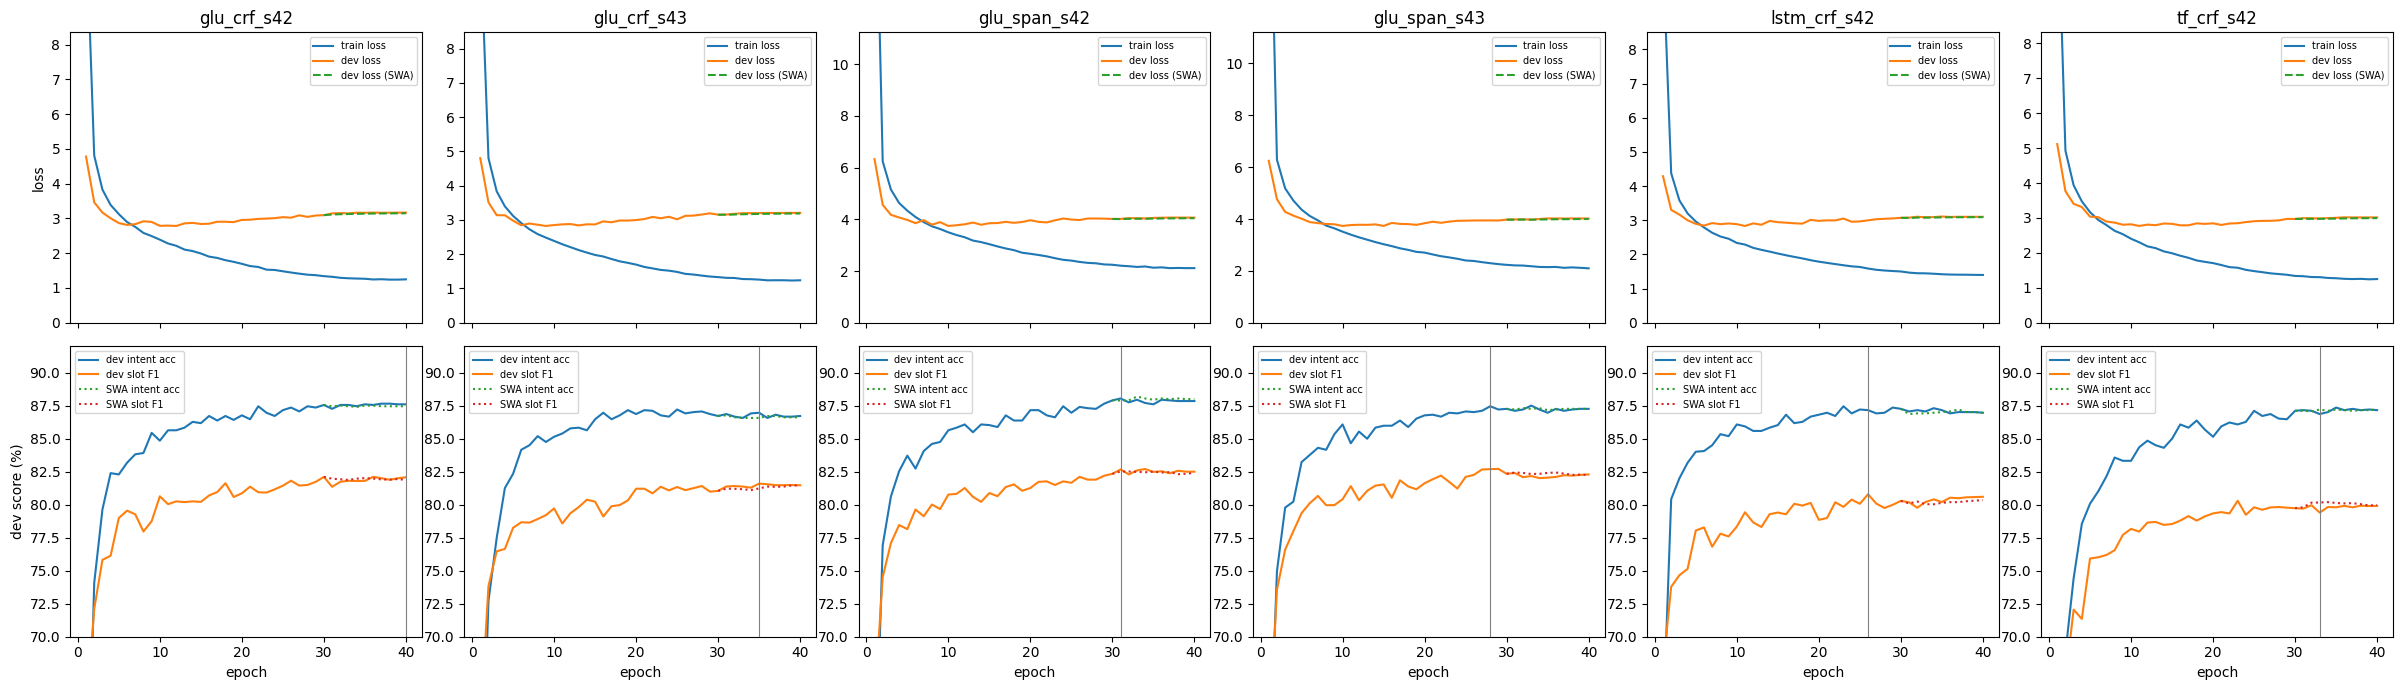

In [16]:
fig, axes = plt.subplots(2, len(MEMBERS), figsize=(4 * len(MEMBERS), 7), sharex=True)
for c, tag in enumerate(histories):
    h = pd.DataFrame(histories[tag])
    ax = axes[0, c]
    ax.plot(h.epoch, h.train_loss, label="train loss")
    ax.plot(h.epoch, h.dev_loss, label="dev loss")
    if "swa_dev_loss" in h:
        ax.plot(h.epoch, h.swa_dev_loss, "--", label="dev loss (SWA)")
    ax.set_title(tag)
    ax.set_ylim(0, max(2.0, float(h.dev_loss.min()) * 3))
    ax.legend(fontsize=7)
    ax = axes[1, c]
    ax.plot(h.epoch, h.dev_intent_acc, label="dev intent acc")
    ax.plot(h.epoch, h.dev_slot_f1, label="dev slot F1")
    if "swa_combined" in h:
        ax.plot(h.epoch, h.swa_intent_acc, ":", label="SWA intent acc")
        ax.plot(h.epoch, h.swa_slot_f1, ":", label="SWA slot F1")
    b = bests[tag]
    ax.axvline(b["epoch"], color="grey", lw=0.8)
    ax.set_ylim(70, 92)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("dev score (%)")
plt.tight_layout()
plt.show()

### Ensemble selection on dev

The six selected member checkpoints are combined; the slot vote threshold is chosen on **dev** only
(highest dev combined score).

In [17]:
tags = list(member_dev)
sweep = {}
for thr in (0.3, 0.4, 0.5, 0.6, 0.7):
    p, s = MixedEnsemble(thr).combine([member_dev[t][0] for t in tags], [member_dev[t][1] for t in tags])
    sweep[thr] = evaluate_outputs(p, s, data["dev"])
display(pd.DataFrame({thr: {k: round(r[k], 2) for k in ("intent_acc", "slot_f1", "combined")} for thr, r in sweep.items()}).T
        .rename_axis("vote threshold"))
THRESHOLD = max(sweep, key=lambda t: sweep[t]["combined"])
selected_dev = sweep[THRESHOLD]

member_table = pd.DataFrame([{"member": t, "selected epoch": bests[t]["epoch"], "weights": bests[t]["kind"],
                              "dev intent acc": round(bests[t]["intent_acc"], 2),
                              "dev slot F1": round(bests[t]["slot_f1"], 2),
                              "dev combined": round(bests[t]["combined"], 2),
                              "train time (min)": round(bests[t]["train_time_s"] / 60, 1),
                              "checkpoint": os.path.relpath(os.path.join(CKPT_DIR, f"{t}.pt"), ROOT)} for t in tags])
display(member_table.set_index("member"))
ENSEMBLE_SPEC = {"members": tags, "threshold": THRESHOLD, "dev": selected_dev,
                 "epochs": {t: bests[t]["epoch"] for t in tags}}
json.dump(ENSEMBLE_SPEC, open(os.path.join(CKPT_DIR, "ensemble.json"), "w"), indent=1)
print(f"SELECTED Stage-2 checkpoint: ensemble of {len(tags)} members, vote threshold {THRESHOLD} | "
      f"dev intent {selected_dev['intent_acc']:.2f} | slot F1 {selected_dev['slot_f1']:.2f} | "
      f"combined {selected_dev['combined']:.2f}")
print("checkpoint files:", os.path.relpath(os.path.join(CKPT_DIR, "ensemble.json"), ROOT), "+",
      ", ".join(f"{t}.pt" for t in tags))

,intent_acc,slot_f1,combined
vote threshold,,,
0.3,88.59,82.72,85.65
0.4,88.59,83.67,86.13
0.5,88.59,83.67,86.13
0.6,88.59,84.29,86.44
0.7,88.59,84.07,86.33


,selected epoch,weights,dev intent acc,dev slot F1,dev combined,train time (min),checkpoint
member,,,,,,,
glu_crf_s42,40,raw,87.60,82.08,84.84,4.7,checkpoints/stage2/glu_crf_s42.pt
glu_crf_s43,35,raw,86.97,81.60,84.28,4.7,checkpoints/stage2/glu_crf_s43.pt
glu_span_s42,31,raw,88.05,82.67,85.36,4.9,checkpoints/stage2/glu_span_s42.pt
glu_span_s43,28,raw,87.46,82.69,85.08,4.8,checkpoints/stage2/glu_span_s43.pt
lstm_crf_s42,26,raw,87.16,80.79,83.98,4.3,checkpoints/stage2/lstm_crf_s42.pt
tf_crf_s42,33,swa,87.21,80.17,83.69,5.3,checkpoints/stage2/tf_crf_s42.pt


SELECTED Stage-2 checkpoint: ensemble of 6 members, vote threshold 0.6 | dev intent 88.59 | slot F1 84.29 | combined 86.44
checkpoint files: checkpoints/stage2/ensemble.json + glu_crf_s42.pt, glu_crf_s43.pt, glu_span_s42.pt, glu_span_s43.pt, lstm_crf_s42.pt, tf_crf_s42.pt


## 8. Stage 2 — final evaluation of the frozen checkpoint

No further training. The ensemble specification and every member checkpoint are **reloaded from disk** into fresh
networks (the frozen word-vector table is also restored from the checkpoints). The reloaded system must reproduce
the selected dev score exactly; only then is the test split evaluated — once.

In [18]:
spec = json.load(open(os.path.join(CKPT_DIR, "ensemble.json")))
frozen_reload = make_frozen(torch.zeros_like(feats["table"])).to(DEVICE)       # values come from the checkpoints
final_members = []
for t in spec["members"]:
    ck = torch.load(os.path.join(CKPT_DIR, f"{t}.pt"), map_location=DEVICE, weights_only=False)
    m = JointNet(ck["config"], feats, labels, frozen_reload).to(DEVICE)
    m.load_state_dict(ck["state"])
    m.eval()
    final_members.append(m)
ensemble = MixedEnsemble(spec["threshold"])

shared = {id(p) for p in frozen_reload.parameters()}
reload_total = frozen_reload.weight.numel() + sum(p.numel() for m in final_members for p in m.parameters()
                                                  if id(p) not in shared)
assert reload_total == STAGE2_TOTAL


def run_ensemble(split):
    outs = [member_outputs(m, eval_batches[split])[:2] for m in final_members]
    p, s = ensemble.combine([o[0] for o in outs], [o[1] for o in outs])
    return p, s, evaluate_outputs(p, s, data[split])


_, _, final_dev = run_ensemble("dev")
for k in ("intent_correct", "tp", "fp", "fn"):
    assert final_dev[k] == spec["dev"][k], f"reloaded ensemble differs from the selected dev result on {k}"
print(f"Validation (reloaded) | intent accuracy {final_dev['intent_acc']:.2f} | slot micro-F1 {final_dev['slot_f1']:.2f}"
      f" | combined {final_dev['combined']:.2f}  == selected dev score")

test_probs, test_spans, final_test = run_ensemble("test")                       # the single test evaluation
print(f"Test                  | intent accuracy {final_test['intent_acc']:.2f} | slot micro-F1 {final_test['slot_f1']:.2f}"
      f" | TP {final_test['tp']} FP {final_test['fp']} FN {final_test['fn']}")

Validation (reloaded) | intent accuracy 88.59 | slot micro-F1 84.29 | combined 86.44  == selected dev score


Test                  | intent accuracy 87.53 | slot micro-F1 81.92 | TP 2223 FP 389 FN 592


## 9. Results table

In [19]:
STAGE2 = {"total_params": STAGE2_TOTAL, "trainable_params": STAGE2_TRAINABLE,
          "epochs": f"{BASE['max_epochs']} per member (selected: {'/'.join(str(e) for e in spec['epochs'].values())})",
          "dev": final_dev, "test": final_test}
rows = []
for name, s in (("Stage-1 system", STAGE1), ("Stage-2 system", STAGE2)):
    if not s:
        continue
    for split in ("dev", "test"):
        rows.append({"Model version": name, "Split": "Validation" if split == "dev" else "Test",
                     "Total # parameters": f"{s['total_params']:,}", "Total # trainable parameters": f"{s['trainable_params']:,}",
                     "Intent accuracy (%)": f"{s[split]['intent_acc']:.2f}", "Slot micro-F1 (%)": f"{s[split]['slot_f1']:.2f}",
                     "Number of epochs": s["epochs"]})
display(pd.DataFrame(rows))

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-2 system,Validation,"18,414,920","14,892,320",88.59,84.29,40 per member (selected: 40/35/31/28/26/33)
1,Stage-2 system,Test,"18,414,920","14,892,320",87.53,81.92,40 per member (selected: 40/35/31/28/26/33)


## 10. Stage 2 — error analysis (test predictions of the frozen system)

Done after the single test evaluation; nothing here feeds back into the model.

In [20]:
seen_values = {(t, s) for e in data["train"] for t, s in e["gold_spans"]}
pred_text = [spans_to_text(s, e["tokens"], labels) for s, e in zip(test_spans, data["test"])]
pred_int = [labels.intents.itos[i] for i in test_probs.argmax(1).tolist()]

# slot recall by whether the gold (type, value) occurs in train, and by span length
rec = {"seen in train": [0, 0], "unseen in train": [0, 0]}
by_len = {}
for e, pred in zip(data["test"], pred_text):
    for g in e["gold_spans"]:
        k = "seen in train" if g in seen_values else "unseen in train"
        rec[k][0] += g in pred
        rec[k][1] += 1
        L = min(len(g[1].split()), 4)
        by_len.setdefault(L, [0, 0])
        by_len[L][0] += g in pred
        by_len[L][1] += 1
display(pd.DataFrame([{"gold slots": k, "count": n, "recall (%)": round(100 * h / n, 1)} for k, (h, n) in rec.items()]))
display(pd.DataFrame([{"span length (words)": ("4+" if L == 4 else L), "count": n, "recall (%)": round(100 * h / n, 1)}
                      for L, (h, n) in sorted(by_len.items())]))

# slot error types
kinds = Counter()
for e, pred in zip(data["test"], pred_text):
    gold = e["gold_spans"]
    for typ, val in gold - pred:
        same_val = any(v == val for t, v in pred - gold)
        overlap = any(set(v.split()) & set(val.split()) for t, v in pred - gold)
        kinds["wrong type (same words)" if same_val else "wrong boundary (overlapping words)" if overlap
              else "missed entirely"] += 1
    for typ, val in pred - gold:
        if not any(set(v.split()) & set(val.split()) for t, v in gold):
            kinds["spurious (no gold overlap)"] += 1
display(pd.DataFrame(kinds.most_common(), columns=["slot error", "count"]))

# per slot type F1 (worst 10 with >= 10 gold) and intent accuracy by intent (worst 8)
per = {}
for e, pred in zip(data["test"], pred_text):
    for t, v in e["gold_spans"] | pred:
        d = per.setdefault(t, [0, 0, 0])
        g, p = (t, v) in e["gold_spans"], (t, v) in pred
        d[0] += g and p
        d[1] += p and not g
        d[2] += g and not p
slot_tab = pd.DataFrame([{"slot type": t, "gold": tp + fn, "F1": round(100 * 2 * tp / max(1, 2 * tp + fp + fn), 1)}
                         for t, (tp, fp, fn) in per.items() if tp + fn >= 10]).sort_values("F1").head(10)
intent_tab = (pd.DataFrame({"gold": [e["intent"] for e in data["test"]], "ok": [p == e["intent"] for p, e in
                                                                                zip(pred_int, data["test"])]})
              .groupby("gold").ok.agg(["count", "mean"]).sort_values("mean").head(8))
intent_tab["mean"] = (100 * intent_tab["mean"]).round(1)
display(slot_tab.set_index("slot type"))
display(intent_tab.rename(columns={"count": "test utterances", "mean": "accuracy (%)"}))
cross = sum(p.split("_", 1)[0] != e["scenario"] for p, e in zip(pred_int, data["test"]) if p != e["intent"])
n_wrong = sum(p != e["intent"] for p, e in zip(pred_int, data["test"]))
print(f"intent errors: {n_wrong} | wrong scenario as well: {cross} ({100 * cross / n_wrong:.1f}%)")
ok = [p == e["intent"] for p, e in zip(pred_int, data["test"])]
for flag, name in ((True, "correct"), (False, "wrong")):
    idx = [i for i, o in enumerate(ok) if o == flag]
    r = score([pred_int[i] for i in idx], [pred_text[i] for i in idx], [data["test"][i] for i in idx])
    print(f"slot micro-F1 on utterances with {name} intent: {r['slot_f1']:.2f} ({len(idx)} utterances)")
exact = sum(p == e["intent"] and s == e["gold_spans"] for p, s, e in zip(pred_int, pred_text, data["test"]))
print(f"exact match (intent and all slots correct): {100 * exact / len(data['test']):.2f}%")

,gold slots,count,recall (%)
0,seen in train,2017,93.2
1,unseen in train,798,43.1


,span length (words),count,recall (%)
0,1,1728,86.5
1,2,746,72.3
2,3,218,58.7
3,4+,123,50.4


,slot error,count
0,missed entirely,391
1,spurious (no gold overlap),172
2,wrong boundary (overlapping words),139
3,wrong type (same words),62


,gold,F1
slot type,,
personal_info,14,48.0
playlist_name,16,51.9
podcast_name,17,52.9
news_topic,49,59.3
radio_name,33,65.6
player_setting,39,65.6
business_type,32,70.0
podcast_descriptor,24,71.4
song_name,39,73.5


,test utterances,accuracy (%)
gold,,
music_settings,6,16.7
music_dislikeness,4,25.0
iot_hue_lighton,3,33.3
audio_volume_other,6,50.0
general_quirky,169,62.1
email_addcontact,12,66.7
transport_query,51,68.6
recommendation_movies,20,75.0


intent errors: 371 | wrong scenario as well: 276 (74.4%)
slot micro-F1 on utterances with correct intent: 84.24 (2603 utterances)
slot micro-F1 on utterances with wrong intent: 57.63 (371 utterances)
exact match (intent and all slots correct): 69.91%


In [21]:
# example errors
def show(i):
    e = data["test"][i]
    print(f"utt   : {e['utt']}\n gold : {e['intent']:<22} {sorted(e['gold_spans'])}\n pred : {pred_int[i]:<22} "
          f"{sorted(pred_text[i])}\n")


errs = [i for i, (p, s, e) in enumerate(zip(pred_int, pred_text, data["test"])) if p != e["intent"] or s != e["gold_spans"]]
unseen = [i for i in errs if any(g not in seen_values and g not in pred_text[i] for g in data["test"][i]["gold_spans"])]
cross_err = [i for i in errs if pred_int[i].split("_", 1)[0] != data["test"][i]["scenario"]]
print("--- missed slot values that never occur in train ---")
for i in unseen[:4]:
    show(i)
print("--- intent predicted in the wrong scenario ---")
for i in cross_err[:4]:
    show(i)

--- missed slot values that never occur in train ---
utt   : i like senatra songs
 gold : music_likeness         [('artist_name', 'senatra')]
 pred : music_likeness         [('music_genre', 'senatra')]

utt   : what's the week's forecast
 gold : weather_query          [('time', "week's")]
 pred : weather_query          [('date', "week's")]

utt   : play music from my rock list
 gold : play_music             [('playlist_name', 'rock list')]
 pred : play_music             [('music_genre', 'rock')]

utt   : what is the exchange rate of us dollar to pound sterling
 gold : news_query             [('news_topic', 'exchange rate of us dollar to pound sterling')]
 pred : qa_currency            [('currency_name', 'pound sterling'), ('currency_name', 'us dollar')]

--- intent predicted in the wrong scenario ---
utt   : pink is all we need
 gold : iot_hue_lightchange    [('color_type', 'pink')]
 pred : music_likeness         [('artist_name', 'pink')]

utt   : and the darkness has fallen
 gold : io